# Mayoristas v4 -- corrige cómo se mide "unidades por ticket" y sube el corte de C3

Motivado por la primera presentación del análisis a Ahorrazo: revisando el
tablero, el equipo miró el segmento Alto ordenado ascendente por venta
promedio por factura y abrió al cliente que quedó en el análisis. Notó que
suma mucho en una factura porque lleva **muchos productos distintos**, no
porque lleve **mucho de cada producto**. `upt` en v3 no distingue esas dos
cosas: agrupa por (ticket, unidad_medida) y suma `unidades` de todas las
líneas, sin importar cuántos productos las componen. Un cliente que compra
15 productos de "Unid" a 2 unidades cada uno suma 30 -- se ve igual que un
cliente que se llevó 30 unidades de un solo producto, y son dos
comportamientos de compra distintos.

**Los dos cambios que este cuaderno explora:**

1. La base de C1 y C2 pasa de `sum(unidades)` a `sum(unidades) / count(distinct producto_id)`
   por (ticket, unidad_medida) -- promedio de unidades por producto distinto,
   no total de la factura. Cambia automáticamente el corte de "factura
   grande" de C2, porque las dos comparten esta misma base -- es la
   consecuencia esperada, no un efecto secundario a evitar.
2. El corte de C3 (venta promedio por factura) sube de percentil 75 (top
   25%) a percentil 90 (top 10%).

Todo lo demás de la metodología v3 (ventana de 12 meses cerrados, las 4
unidades de medida con volumen real, C3 global en guaraníes, el piso de 40%
para C2) se mantiene igual. Este cuaderno no escribe nada a la base: es
exploración y prototipo, igual que hizo `analisis_mayoristas_v3.ipynb` antes
de portar la metodología a dbt.

**Nota sobre este cuaderno:** las celdas de abajo no se ejecutaron todavía
-- la sesión en la que se escribió no tenía conexión a la base (VPN sin
levantar, puerto 1433 inalcanzable). Córralo de punta a punta antes de
confiar en ningún número de acá abajo.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))

from conexion_bd import conexion_bd

pd.set_option("display.float_format", "{:,.2f}".format)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "text.color": "#0b0b0b",
    "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.size": 11,
})

caja_estilo = dict(
    patch_artist=True,
    boxprops=dict(facecolor="#cde2fb", edgecolor="#2a78d6"),
    medianprops=dict(color="#184f95", linewidth=2),
    whiskerprops=dict(color="#2a78d6"),
    capprops=dict(color="#2a78d6"),
    flierprops=dict(markeredgecolor="#2a78d6", markersize=3, alpha=0.4),
    showmeans=True,
    meanprops=dict(marker="D", markerfacecolor="#eb6834", markeredgecolor="#eb6834", markersize=6),
)

## Constantes de esta corrida

`CLIENTE_MOTIVADOR` es el cliente que revisó el equipo de Ahorrazo en la
reunión (id `3799868` según quedó anotado). **No se pudo confirmar contra la
base** en la sesión en la que se armó este cuaderno -- se probó como
`cliente_id_limpio`, como `cliente_id` crudo exacto, y con búsqueda parcial
(`LIKE '%3799868%'`) contra las 238M de filas de `Ventas_Ahorrazo`, sin
ningún resultado. Puede ser una transcripción distinta a como quedó guardado
el dato. La celda de la sección 1 busca este id y, si no aparece, muestra
el segmento Alto ordenado igual que en la reunión para ubicarlo a mano --
corregir la constante acá abajo con el id real y volver a correr desde acá.

In [2]:
CLIENTE_MOTIVADOR = "3799869"  # corregido: error de tipeo del "3799868" anotado en la reunion

# Las dos facturas que se pidió revisar. La segunda vino sin el prefijo de
# timbrado en el mensaje original -- se arma con LIKE en vez de igualdad
# exacta hasta confirmar el timbrado real.
FACTURA_1 = "15673870_005-018-0209657"
FACTURA_2_SUFIJO = "005-005-0144608"

UNIDADES_MEDIDA_UPT = ["Unid", "KILOS", "LITROS", "Pack"]
PCT_GRANDES_MINIMO = 0.40  # var mayoristas_pct_grandes_minimo en dbt, sin cambios
MULTIPLICADOR_IQR = 3  # sin cambios respecto a v3
C1_C3_PERCENTIL_V3 = 0.75  # como seguía C1 (sin cambios) y como estaba C3 antes
C3_PERCENTIL_V4 = 0.90  # pedido de la reunión: top 10% en vez de top 25%

## Carga

Mismo insumo que v3: `intermediate.int_ventas_12m_tabla` (ventana de 12
meses cerrados + todas las exclusiones de negocio ya aplicadas) con
`unidad_medida` sumada desde `staging.stg_productos`. Se agrega
`producto_id` a la selección -- v3 ya lo trae, pero acá hace falta explícito
para poder contar productos distintos por ticket, que es el núcleo del
cambio de este cuaderno.

In [3]:
SQL_VENTAS_CON_UNIDAD = """
SELECT
    v.fecha_venta,
    v.pdv_id,
    v.ticket_id,
    v.cliente_id_limpio,
    v.producto_id,
    p.unidad_medida,
    v.unidades,
    v.venta_gs
FROM intermediate.int_ventas_12m_tabla v
INNER JOIN staging.stg_productos p
    ON v.producto_id = p.producto_id
WHERE v.cliente_id_limpio IS NOT NULL
"""

with conexion_bd() as conn:
    ventas = pd.read_sql_query(SQL_VENTAS_CON_UNIDAD, conn)

ventas["fecha_venta"] = pd.to_datetime(ventas["fecha_venta"])
for col in ("cliente_id_limpio", "producto_id", "pdv_id", "ticket_id"):
    ventas[col] = ventas[col].astype(str)

print(f"Filas cargadas: {len(ventas):,}")
print(f"Clientes unicos: {ventas['cliente_id_limpio'].nunique():,}")
print(f"Unidades de medida presentes: {sorted(ventas['unidad_medida'].unique())}")
ventas.head()

Filas cargadas: 55,245,749
Clientes unicos: 384,980
Unidades de medida presentes: ['Blis', 'KILOS', 'LITROS', 'Metros', 'Pack', 'Ramo', 'Unid']


  fecha_venta pdv_id         ticket_id cliente_id_limpio producto_id unidad_medida  unidades  venta_gs
0  2026-07-11      5  _005-003-0096196           1161285     9933875          Unid      1.00  3,650.00
1  2026-07-11      3  _003-014-0273857           1234503     9933875          Unid      1.00  3,650.00
2  2026-07-11      3  _003-013-0345239           1420843     9933875          Unid      1.00  3,650.00
3  2026-07-11      5  _005-016-0288799           1441445     9933875          Unid      1.00  3,650.00
4  2026-07-11      6  _006-017-0093936           1441959     9933875          Unid      1.00  3,650.00

## 1) El caso que motivó el cambio

Primero se busca al cliente ejemplo de la reunion del 15/09/2026. Si no aparece, se
reproduce lo que hizo el equipo en la reunión -- el segmento Alto de la
tabla ya productiva (`marts_mayoristas.mayoristas_v3_resumen`), ordenado
ascendente por venta promedio por factura -- para ubicarlo a mano entre los
primeros 30 y corregir `CLIENTE_MOTIVADOR` arriba.

In [4]:
tiene_cliente = (ventas["cliente_id_limpio"] == CLIENTE_MOTIVADOR).any()

if tiene_cliente:
    print(f"Cliente {CLIENTE_MOTIVADOR} encontrado en la ventana de 12 meses.")
else:
    print(
        f"Cliente {CLIENTE_MOTIVADOR} NO aparece en la ventana de 12 meses "
        f"(cliente_id_limpio). Mostrando el segmento Alto ordenado igual que "
        f"en la reunión para ubicarlo a mano."
    )
    SQL_ALTO_ASCENDENTE = """
    SELECT TOP 30 cliente_id_limpio, venta_promedio_ticket, ventas_totales
    FROM marts_mayoristas.mayoristas_v3_resumen
    WHERE nivel_mayorista = 'Alto'
    ORDER BY venta_promedio_ticket ASC
    """
    with conexion_bd() as conn:
        alto_ascendente = pd.read_sql_query(SQL_ALTO_ASCENDENTE, conn)
    alto_ascendente["cliente_id_limpio"] = alto_ascendente["cliente_id_limpio"].astype(str)
    display(alto_ascendente)

Cliente 3799869 encontrado en la ventana de 12 meses.


In [ ]:
if tiene_cliente:
    facturas_cliente = ventas[
        (ventas["cliente_id_limpio"] == CLIENTE_MOTIVADOR)
        & (
            (ventas["ticket_id"] == FACTURA_1)
            | (ventas["ticket_id"].str.endswith(FACTURA_2_SUFIJO))
        )
    ].sort_values(["ticket_id", "unidad_medida", "producto_id"])

    print(f"Registros encontrados para las 2 facturas: {len(facturas_cliente)}")
    display(facturas_cliente)

    if facturas_cliente.empty:
        print(
            "El cliente existe en la ventana pero no con estos ticket_id exactos -- "
            "revisar todas sus facturas:"
        )
        display(
            ventas[ventas["cliente_id_limpio"] == CLIENTE_MOTIVADOR]
            .sort_values(["ticket_id", "unidad_medida"])
        )

## 2) El cálculo viejo contra el propuesto, en las facturas puntuales

Por cada (ticket, unidad_medida): **viejo** = `sum(unidades)` (lo que hoy
alimenta C1/C2 en producción). **nuevo** = `sum(unidades) / count(distinct
producto_id)` -- promedio de unidades por producto distinto, que es lo que
pidió el equipo de Ahorrazo ("cantidad de ítems" = productos distintos, no
cada línea de venta).

In [6]:
if tiene_cliente and not facturas_cliente.empty:
    comparacion_caso = (
        facturas_cliente.groupby(["ticket_id", "unidad_medida"])
        .agg(
            unidades_suma_vieja=("unidades", "sum"),
            productos_distintos=("producto_id", "nunique"),
            lineas=("producto_id", "count"),
        )
        .reset_index()
    )
    comparacion_caso["unidades_promedio_nueva"] = (
        comparacion_caso["unidades_suma_vieja"] / comparacion_caso["productos_distintos"]
    )
    display(comparacion_caso)

                  ticket_id unidad_medida  unidades_suma_vieja  productos_distintos  lineas  unidades_promedio_nueva
0  15673870_005-018-0209657          Unid                70.00                    9       9                     7.78
1          _005-005-0144608         KILOS                 1.74                    1       1                     1.74
2          _005-005-0144608          Unid               108.00                   32      32                     3.38

## 3) Reconstruir la base de C1/C2 con la fórmula nueva

Mismo grano que v3 (cliente, unidad_medida, ticket), pero `unidades` pasa a
ser el promedio por producto distinto en vez de la suma. Se calculan las dos
versiones lado a lado (`_v3` con la fórmula vieja, `_v4` con la nueva) para
poder comparar todo lo que sigue, no solo el resultado final.

In [7]:
base_unidad = ventas[ventas["unidad_medida"].isin(UNIDADES_MEDIDA_UPT)].copy()

ticket_cliente_unidad = (
    base_unidad.groupby(["cliente_id_limpio", "unidad_medida", "ticket_id"], dropna=False)
    .agg(
        unidades_suma=("unidades", "sum"),
        productos_distintos=("producto_id", "nunique"),
    )
    .reset_index()
)
ticket_cliente_unidad = ticket_cliente_unidad[ticket_cliente_unidad["unidades_suma"] > 0]

ticket_cliente_unidad["unidades_v3"] = ticket_cliente_unidad["unidades_suma"]
ticket_cliente_unidad["unidades_v4"] = (
    ticket_cliente_unidad["unidades_suma"] / ticket_cliente_unidad["productos_distintos"]
)

print(f"Tickets x unidad_medida: {len(ticket_cliente_unidad):,}")
ticket_cliente_unidad.groupby("unidad_medida")[["unidades_v3", "unidades_v4", "productos_distintos"]].describe()

Tickets x unidad_medida: 7,416,353


               unidades_v3                                            unidades_v4                                        productos_distintos                                       
                     count  mean   std  min  25%  50%   75%      max        count mean  std  min  25%  50%  75%      max               count mean   std  min  25%  50%   75%    max
unidad_medida                                                                                                                                                                      
KILOS         3,104,313.00  5.47  6.54 0.00 1.40 3.39  7.33 1,124.50 3,104,313.00 1.07 2.19 0.00 0.56 0.84 1.21 1,124.50        3,104,313.00 5.47  4.90 1.00 2.00 4.00  8.00  61.00
LITROS          158,696.00  2.54  2.22 0.06 1.00 2.00  3.00    60.00   158,696.00 2.50 2.18 0.06 1.00 2.00 3.00    60.00          158,696.00 1.02  0.14 1.00 1.00 1.00  1.00   3.00
Pack             47,653.00  1.39  1.80 0.14 1.00 1.00  1.00   126.00    47,653.00 1.28 1.23 0.14 1.0

## 4) Boxplots -- cómo cambia la distribución por unidad de medida

Mismo estilo que la exploración de v3 (escala log, caja + media + mediana
anotadas), esta vez comparando `unidades_v3` (suma) contra `unidades_v4`
(promedio por producto distinto) una unidad de medida a la vez.

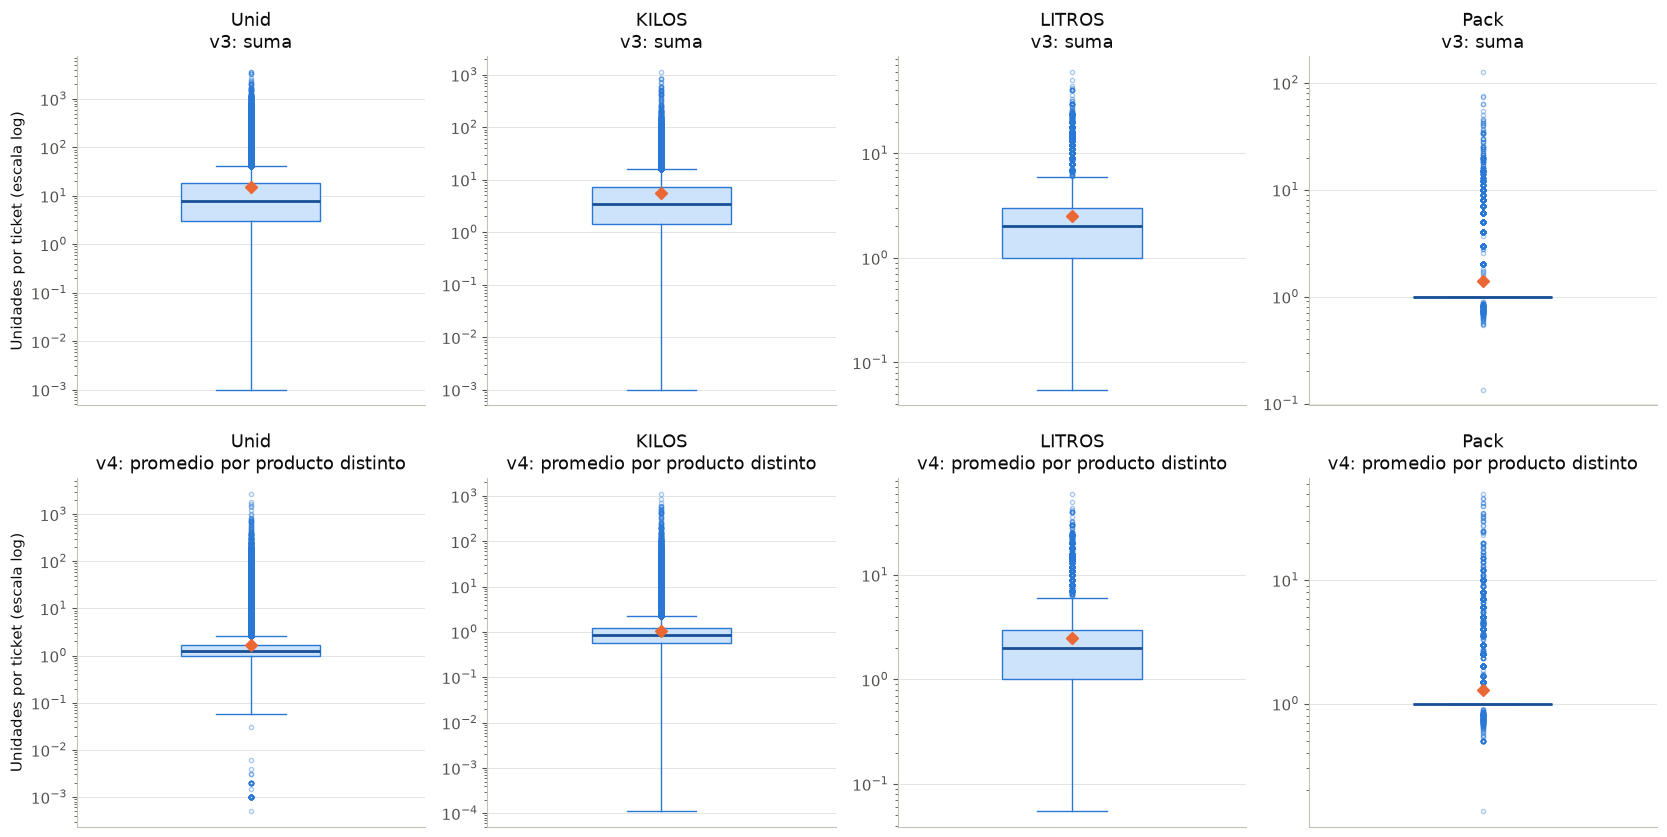

In [8]:
orden_unidades = UNIDADES_MEDIDA_UPT
paleta_por_unidad = dict(zip(orden_unidades, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

fig, axes = plt.subplots(2, len(orden_unidades), figsize=(4.2 * len(orden_unidades), 8.5), sharex="col")

for i, unidad in enumerate(orden_unidades):
    datos = ticket_cliente_unidad[ticket_cliente_unidad["unidad_medida"] == unidad]

    axes[0, i].boxplot(datos["unidades_v3"], vert=True, widths=0.4, **caja_estilo)
    axes[0, i].set_yscale("log")
    axes[0, i].set_xticks([])
    axes[0, i].set_title(f"{unidad}\nv3: suma")

    axes[1, i].boxplot(datos["unidades_v4"], vert=True, widths=0.4, **caja_estilo)
    axes[1, i].set_yscale("log")
    axes[1, i].set_xticks([])
    axes[1, i].set_title(f"{unidad}\nv4: promedio por producto distinto")

axes[0, 0].set_ylabel("Unidades por ticket (escala log)")
axes[1, 0].set_ylabel("Unidades por ticket (escala log)")
plt.tight_layout()
plt.show()

## 5) El corte de "factura grande" (C2), recalculado

`Q3 + 3×IQR` sobre `unidades_v4`, con el mismo caso especial que ya vive en
`int_mayoristas_v3_umbral_ticket.sql`: cuando el IQR real (`q3 - q1`) da 0,
el corte pasa a ser `2×Q3` en vez de aplicar la fórmula general. La celda
imprime explícitamente qué unidades caen en ese caso bajo la distribución
nueva -- **no asumir que sigue siendo solo Pack**.

In [9]:
def calcular_umbral_ticket_grande(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr <= 0:
        return pd.Series({
            "q1": q1, "q3": q3, "iqr_real": iqr, "iqr_aplicado": q3,
            "umbral_ticket_grande": 2 * q3, "caso_especial_iqr_cero": True,
        })
    return pd.Series({
        "q1": q1, "q3": q3, "iqr_real": iqr, "iqr_aplicado": iqr,
        "umbral_ticket_grande": q3 + MULTIPLICADOR_IQR * iqr, "caso_especial_iqr_cero": False,
    })


umbral_ticket_v4 = (
    ticket_cliente_unidad.groupby("unidad_medida")["unidades_v4"]
    .apply(calcular_umbral_ticket_grande)
    .unstack()
)

print("Unidades con IQR real = 0 bajo la nueva distribuci\u00f3n (usan 2\u00d7Q3):")
print(umbral_ticket_v4.index[umbral_ticket_v4["caso_especial_iqr_cero"]].tolist())
umbral_ticket_v4

Unidades con IQR real = 0 bajo la nueva distribución (usan 2×Q3):
['Pack']


                q1   q3 iqr_real iqr_aplicado umbral_ticket_grande caso_especial_iqr_cero
unidad_medida                                                                            
KILOS         0.56 1.21     0.65         0.65                 3.17                  False
LITROS        1.00 3.00     2.00         2.00                 9.00                  False
Pack          1.00 1.00     0.00         1.00                 2.00                   True
Unid          1.00 1.64     0.64         0.64                 3.57                  False

## 6) C1 y C2 por cliente, con la base nueva

Mismo esquema que v3: `upt` = promedio de `unidades_v4` entre los tickets
del cliente en esa unidad; `pct_tickets_grandes` = proporción de tickets que
superaron el corte de arriba. C1 sigue en percentil 75 (top 25%, sin cambios
pedidos); C2 hereda el piso mínimo de 40% sin cambios.

In [10]:
ticket_cliente_unidad = ticket_cliente_unidad.merge(
    umbral_ticket_v4[["umbral_ticket_grande"]], on="unidad_medida", how="left"
)
ticket_cliente_unidad["ticket_grande_v4"] = (
    ticket_cliente_unidad["unidades_v4"] > ticket_cliente_unidad["umbral_ticket_grande"]
)

metricas_por_unidad_v4 = (
    ticket_cliente_unidad.groupby(["cliente_id_limpio", "unidad_medida"])
    .agg(
        tickets_unicos=("ticket_id", "count"),
        upt=("unidades_v4", "mean"),
        pct_tickets_grandes=("ticket_grande_v4", "mean"),
    )
    .reset_index()
)

umbrales_cliente_v4 = metricas_por_unidad_v4.groupby("unidad_medida").agg(
    umbral_upt=("upt", lambda s: s.quantile(C1_C3_PERCENTIL_V3)),
    umbral_pct=("pct_tickets_grandes", lambda s: max(PCT_GRANDES_MINIMO, s.quantile(C1_C3_PERCENTIL_V3))),
)

metricas_por_unidad_v4 = metricas_por_unidad_v4.merge(umbrales_cliente_v4, on="unidad_medida", how="left")
metricas_por_unidad_v4["c1_upt_alto"] = metricas_por_unidad_v4["upt"] >= metricas_por_unidad_v4["umbral_upt"]
metricas_por_unidad_v4["c2_pct_grandes_alto"] = (
    metricas_por_unidad_v4["pct_tickets_grandes"] >= metricas_por_unidad_v4["umbral_pct"]
)

umbrales_cliente_v4

               umbral_upt  umbral_pct
unidad_medida                        
KILOS                1.22        0.40
LITROS               3.00        0.40
Pack                 1.00        0.40
Unid                 1.70        0.40

## 7) C3 con el corte más exigente (percentil 90)

Sin cambios en la definición (venta promedio por factura, todas las
unidades de medida juntas): solo se mueve el percentil de 0,75 a 0,90.

In [11]:
c1_c2_cliente_v4 = (
    metricas_por_unidad_v4.groupby("cliente_id_limpio")
    .agg(c1_upt_alto=("c1_upt_alto", "any"), c2_pct_grandes_alto=("c2_pct_grandes_alto", "any"))
    .reset_index()
)

venta_por_ticket = (
    ventas.groupby(["cliente_id_limpio", "ticket_id"], dropna=False)["venta_gs"]
    .sum()
    .reset_index()
)
ventas_cliente = (
    venta_por_ticket.groupby("cliente_id_limpio")["venta_gs"]
    .agg(venta_promedio_ticket="mean", ventas_totales="sum")
    .reset_index()
)

umbral_c3_v4 = ventas_cliente["venta_promedio_ticket"].quantile(C3_PERCENTIL_V4)
umbral_c3_v3_referencia = ventas_cliente["venta_promedio_ticket"].quantile(C1_C3_PERCENTIL_V3)
print(f"Umbral C3 v4 (percentil 90): {umbral_c3_v4:,.2f} Gs")
print(f"Umbral C3 v3, de referencia (percentil 75): {umbral_c3_v3_referencia:,.2f} Gs")

resultado_v4 = ventas_cliente.merge(c1_c2_cliente_v4, on="cliente_id_limpio", how="left")
resultado_v4[["c1_upt_alto", "c2_pct_grandes_alto"]] = resultado_v4[
    ["c1_upt_alto", "c2_pct_grandes_alto"]
].fillna(False)
resultado_v4["c3_ventas_alto"] = resultado_v4["venta_promedio_ticket"] >= umbral_c3_v4

resultado_v4["puntaje"] = (
    resultado_v4["c1_upt_alto"].astype(int)
    + resultado_v4["c2_pct_grandes_alto"].astype(int)
    + resultado_v4["c3_ventas_alto"].astype(int)
)
niveles_por_puntaje = {3: "Alto", 2: "Medio", 1: "Potencial", 0: "Minorista"}
resultado_v4["nivel_mayorista"] = resultado_v4["puntaje"].map(niveles_por_puntaje)

resultado_v4["nivel_mayorista"].value_counts()

Umbral C3 v4 (percentil 90): 353,278.70 Gs
Umbral C3 v3, de referencia (percentil 75): 208,967.49 Gs


nivel_mayorista
Minorista    210619
Potencial    130404
Medio         38416
Alto           5541
Name: count, dtype: int64

## 8) v4 contra v3 -- qué tanto se movieron los segmentos

Se trae la tabla real de producción (`marts_mayoristas.mayoristas_v3_resumen`)
para comparar contra `resultado_v4`, cliente por cliente. La comparación
mezcla dos cambios a la vez (base de C1/C2 + corte de C3): si algo llama la
atención, conviene volver a correr las secciones 6 y 7 aislando un cambio
por vez antes de sacar conclusiones.

In [12]:
SQL_RESUMEN_V3 = """
SELECT cliente_id_limpio, venta_promedio_ticket, ventas_totales,
       c1_upt_alto, c2_pct_grandes_alto, c3_ventas_alto, puntaje, nivel_mayorista
FROM marts_mayoristas.mayoristas_v3_resumen
"""
with conexion_bd() as conn:
    resultado_v3 = pd.read_sql_query(SQL_RESUMEN_V3, conn)

resultado_v3["cliente_id_limpio"] = resultado_v3["cliente_id_limpio"].astype(str)
for col in ("c1_upt_alto", "c2_pct_grandes_alto", "c3_ventas_alto"):
    resultado_v3[col] = resultado_v3[col].astype(bool)

orden_niveles = ["Alto", "Medio", "Potencial", "Minorista"]
comparacion_niveles = pd.DataFrame({
    "v3 (producci\u00f3n)": resultado_v3["nivel_mayorista"].value_counts().reindex(orden_niveles),
    "v4 (este cuaderno)": resultado_v4["nivel_mayorista"].value_counts().reindex(orden_niveles),
})
comparacion_niveles["diferencia"] = comparacion_niveles["v4 (este cuaderno)"] - comparacion_niveles["v3 (producci\u00f3n)"]
display(comparacion_niveles)

transicion = resultado_v3[["cliente_id_limpio", "nivel_mayorista"]].merge(
    resultado_v4[["cliente_id_limpio", "nivel_mayorista"]],
    on="cliente_id_limpio", how="outer", suffixes=("_v3", "_v4"),
)
tabla_transicion = pd.crosstab(
    transicion["nivel_mayorista_v3"], transicion["nivel_mayorista_v4"]
).reindex(index=orden_niveles, columns=orden_niveles)
print("Filas: nivel en v3. Columnas: nivel en v4. La diagonal es qui\u00e9n no se movi\u00f3.")
display(tabla_transicion)

Filas: nivel en v3. Columnas: nivel en v4. La diagonal es quién no se movió.


                 v3 (producción)  v4 (este cuaderno)  diferencia
nivel_mayorista                                                 
Alto                       15104                5541       -9563
Medio                      71604               38416      -33188
Potencial                  67064              130404       63340
Minorista                 231208              210619      -20589

nivel_mayorista_v4  Alto  Medio  Potencial  Minorista
nivel_mayorista_v3                                   
Alto                3801   8407       2697        199
Medio               1573  17198      34050      18783
Potencial            167   5658      39177      22062
Minorista              0   7153      54480     169575

In [13]:
if tiene_cliente:
    print("Cliente motivador -- v3 (producci\u00f3n):")
    display(resultado_v3[resultado_v3["cliente_id_limpio"] == CLIENTE_MOTIVADOR])
    print("Cliente motivador -- v4 (este cuaderno):")
    display(resultado_v4[resultado_v4["cliente_id_limpio"] == CLIENTE_MOTIVADOR])
else:
    print(f"No se puede validar el cliente motivador: {CLIENTE_MOTIVADOR} no est\u00e1 en la ventana. Ver secci\u00f3n 1.")

Cliente motivador -- v3 (producción):
Cliente motivador -- v4 (este cuaderno):


       cliente_id_limpio  venta_promedio_ticket  ventas_totales  c1_upt_alto  c2_pct_grandes_alto  c3_ventas_alto  puntaje nivel_mayorista
381697           3799869             209,096.44   30,737,176.20         True                 True            True        3            Alto

       cliente_id_limpio  venta_promedio_ticket  ventas_totales  c1_upt_alto  c2_pct_grandes_alto  c3_ventas_alto  puntaje nivel_mayorista
130950           3799869             209,096.44   30,737,176.20         True                 True           False        2           Medio

## Qué queda pendiente antes de portar esto a dbt

- **Confirmar el id real del cliente motivador** si la sección 1 no lo
  encontró, y validar que su clasificación en v4 ya tenga sentido de
  negocio (se llevó poco de cada producto -> no debería cumplir C1/C2 tan
  fácil como antes).
- **Revisar el resultado de la sección 5**: si alguna unidad de medida
  distinta a Pack empieza a necesitar el caso especial de IQR=0 bajo la
  nueva distribución, hay que decidir si el fallback `2×Q3` sigue siendo el
  criterio correcto para esa unidad también, o si hace falta uno distinto.
- **Mirar la tabla de transición (sección 8)** con el equipo de Ahorrazo
  antes de portar a dbt: cuántos clientes bajan de nivel solo por el cambio
  de fórmula de C1/C2, cuántos por el corte más exigente de C3, y si el
  tamaño del movimiento es el esperado.
- Una vez validado, el port a dbt toca `int_mayoristas_v3_tickets_por_unidad.sql`
  (agregar `count(distinct producto_id)` y dividir), `int_mayoristas_v3_umbral_ticket.sql`
  (nada de lógica nueva, solo corre sobre la columna ya dividida) y
  `mayoristas_v3_resumen.sql` (mover `percentile_cont(0.75)` a una var nueva
  en 0.90 para `umbral_c3`).